# 01 · DaTSCAN / SPECT Dopamine Imaging EDA
> *The primary biomarker in PPMI — measuring how much dopamine transporter is left in the brain.*

## Background: What is DaTSCAN?

**DaTSCAN** uses a radioactive tracer (¹²³I-ioflupane) that binds to **Dopamine Transporter (DAT)** proteins on dopamine neurons.

1. Tracer injected → travels to brain → binds to DAT proteins
2. SPECT camera detects radiation → creates a map of DAT density
3. More binding = more dopamine neurons = healthier dopamine system

**Why it matters for PD:** As dopamine neurons die, DAT binding decreases. DaTSCAN can detect this *before* motor symptoms are severe enough for a clinical diagnosis.

**Key measurement — Striatal Binding Ratio (SBR):**
> SBR = (tracer uptake in brain region) / (tracer uptake in white matter) − 1

White matter has no DAT, so it's the reference. An SBR of 2.0 means the region has 3× more tracer than white matter.
- **Healthy controls:** SBR typically > 1.5 in putamen
- **PD patients:** SBR can drop to < 1.0 in putamen

**Brain regions measured:**
- **Striatum** = Caudate + Putamen (combined)
- **Caudate nucleus** = involved in learning/motivation; less affected early in PD
- **Putamen** = most affected early in PD; the most sensitive region for diagnosis
- **L_ / R_ prefixes** = left / right hemisphere

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data Files

In [3]:
scan_log = pd.read_csv(DATA_DIR / 'Dopamine_Imaging_12Nov2026.csv')
acq_meta = pd.read_csv(DATA_DIR / 'Xing_Core_Lab_-_DATSCAN_acquisition_metadata_12Nov2026.csv')
sbr      = pd.read_csv(DATA_DIR / 'Xing_Core_Lab_-_Quant_SBR_12Nov2026.csv')
vis_read = pd.read_csv(DATA_DIR / 'Xing_Core_Lab_-_Visual_Read_12Nov2026.csv')
for name, df in [('Scan Log', scan_log), ('Acquisition Metadata', acq_meta),
                 ('Quant SBR', sbr), ('Visual Read', vis_read)]:
    print(f'{name:30s}: {len(df):>6,} rows | {df["PATNO"].nunique()} participants')

Scan Log                      : 16,069 rows | 7745 participants
Acquisition Metadata          : 11,967 rows | 5408 participants
Quant SBR                     : 10,808 rows | 4899 participants
Visual Read                   :  2,334 rows | 2325 participants


## Column Reference

### Scan Log (`Dopamine_Imaging`)
| Column | Meaning |
|--------|---------|
| `PATNO` | Participant ID |
| `EVENT_ID` | Visit code |
| `DATSCAN` | Scan completed? 1=Yes 0=No |
| `DATSCANTRC` | Tracer: 1=¹²³I-DaTscan, 2=⁹⁹mTc-TRODAT-1 |
| `VSINTRPT` | Visual interpretation: 1=Normal, 2=Abnormal |
| `INFODT` | Date info recorded (MM/YYYY) |

### Acquisition Metadata (`Xing_Core_Lab_-_DATSCAN_acquisition_metadata`)
| Column | Meaning |
|--------|---------|
| `DATSCAN_LIGAND` | Radiopharmaceutical name |
| `DATSCAN_TOTAL_DOSE_CALC` | Injected dose in MBq (radioactivity amount) |
| `DATSCAN_IMAGE_ACCEPTABLE` | QC pass: Yes/No |
| `DATSCAN_START_TIME` | When SPECT scan began |

### Quantitative SBR (`Xing_Core_Lab_-_Quant_SBR`)
| Column | Meaning |
|--------|---------|
| `DATSCAN_ANALYZED` | Was scan analyzable? Yes/No |
| `STRIATUM_REF_CWM` | Bilateral striatum SBR (vs cerebral white matter) |
| `CAUDATE_REF_CWM` | Bilateral caudate SBR |
| `PUTAMEN_REF_CWM` | Bilateral putamen SBR |
| `*_L_REF_CWM` | Left hemisphere version |
| `*_R_REF_CWM` | Right hemisphere version |
| `*_PRECAUDATE_*` | Anterior part of caudate |
| `*_ANTPUTAMEN_*` | Anterior putamen (most sensitive to PD) |
| `*_POSTPUTAMEN_*` | Posterior putamen |

### Visual Read (`Xing_Core_Lab_-_Visual_Read`)
| Column | Meaning |
|--------|---------|
| `DATSCAN_VISINTRP` | Radiologist overall interpretation: "positive"=abnormal, "negative"=normal |

## 1 · Scan Completion per Visit

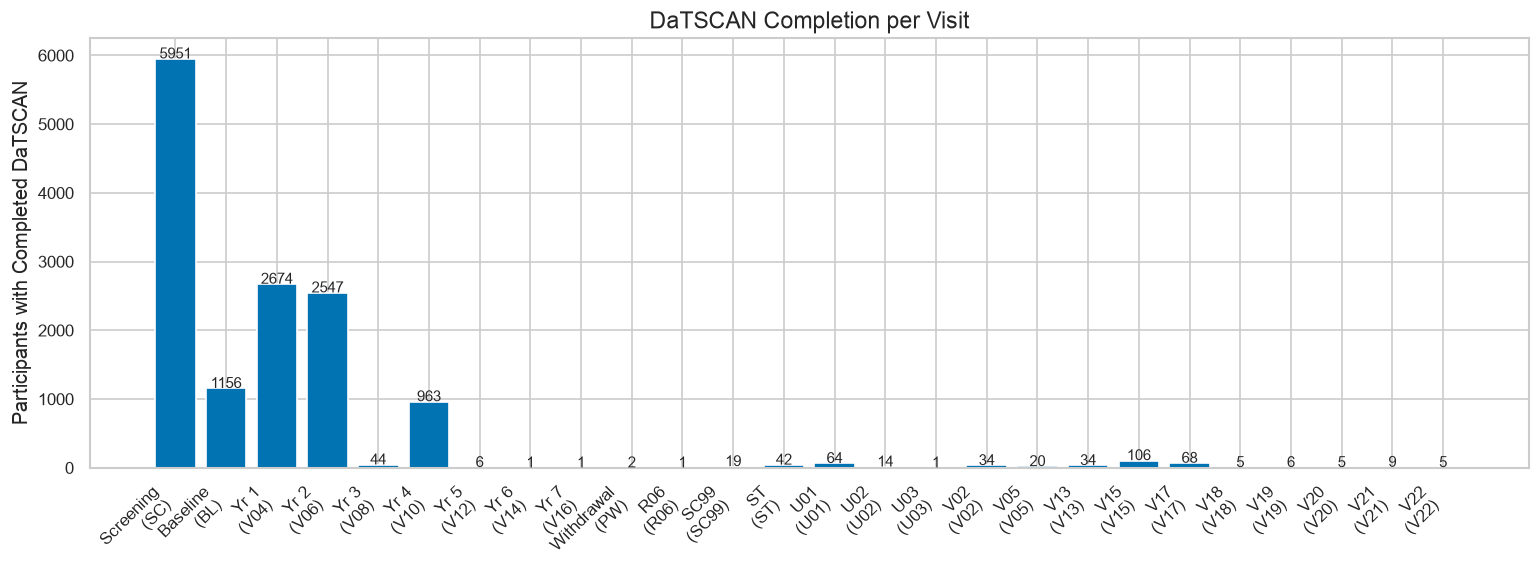

Total scan records: 16,069 | Completed: 13,783


In [4]:
completed = scan_log[scan_log['DATSCAN'] == 1]
visits = ordered_visits(scan_log['EVENT_ID'])
vc = completed.groupby('EVENT_ID')['PATNO'].nunique().reindex(visits).dropna()

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(range(len(vc)), vc.values, color=sns.color_palette('colorblind')[0])
ax.set_xticks(range(len(vc)))
ax.set_xticklabels([f'{VISIT_LABELS.get(v,v)}\n({v})' for v in vc.index], rotation=45, ha='right')
ax.set_ylabel('Participants with Completed DaTSCAN')
ax.set_title('DaTSCAN Completion per Visit')
for b, v in zip(bars, vc.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+5, str(int(v)), ha='center', fontsize=9)
plt.tight_layout(); plt.show()
print(f'Total scan records: {len(scan_log):,} | Completed: {len(completed):,}')

## 2 · Radiotracer Used

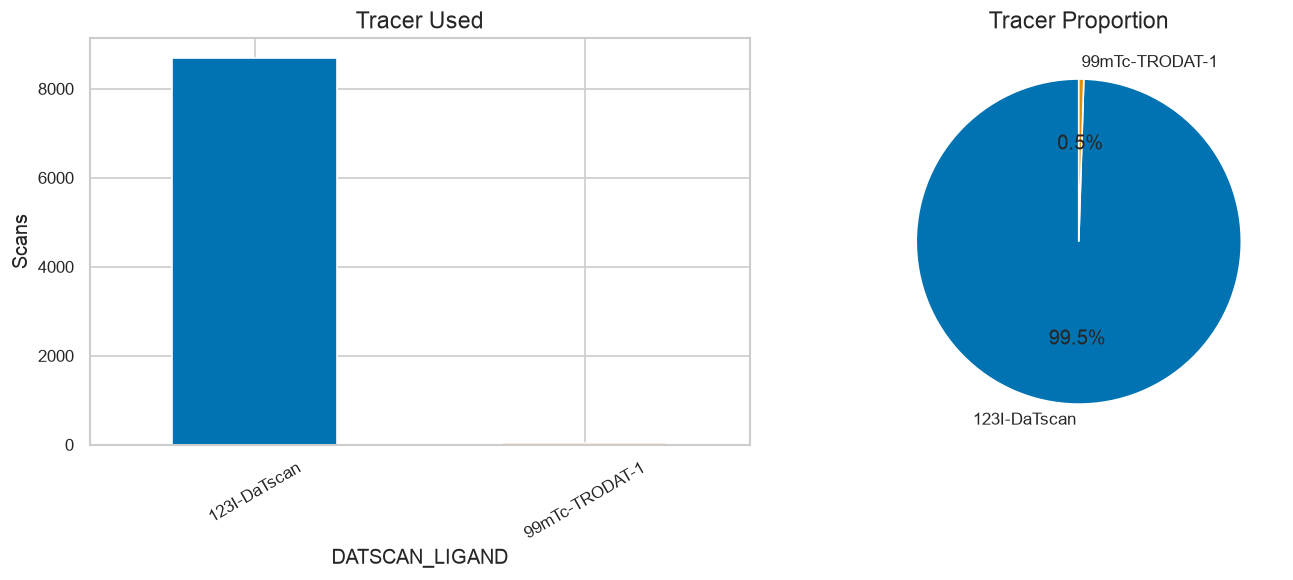

DATSCAN_LIGAND
123I-DaTscan      8698
99mTc-TRODAT-1      43


In [5]:
lig = acq_meta['DATSCAN_LIGAND'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
lig.plot(kind='bar', ax=axes[0], color=sns.color_palette('colorblind', len(lig)), edgecolor='white')
axes[0].set_title('Tracer Used'); axes[0].set_ylabel('Scans'); axes[0].tick_params(axis='x', rotation=30)
axes[1].pie(lig.values, labels=lig.index, autopct='%1.1f%%',
            colors=sns.color_palette('colorblind', len(lig)), startangle=90)
axes[1].set_title('Tracer Proportion')
plt.tight_layout(); plt.show(); print(lig.to_string())

## 3 · Image Quality Acceptance Rate

Every scan is reviewed by the Xing Core Lab. Only 'acceptable' scans are used for analysis.

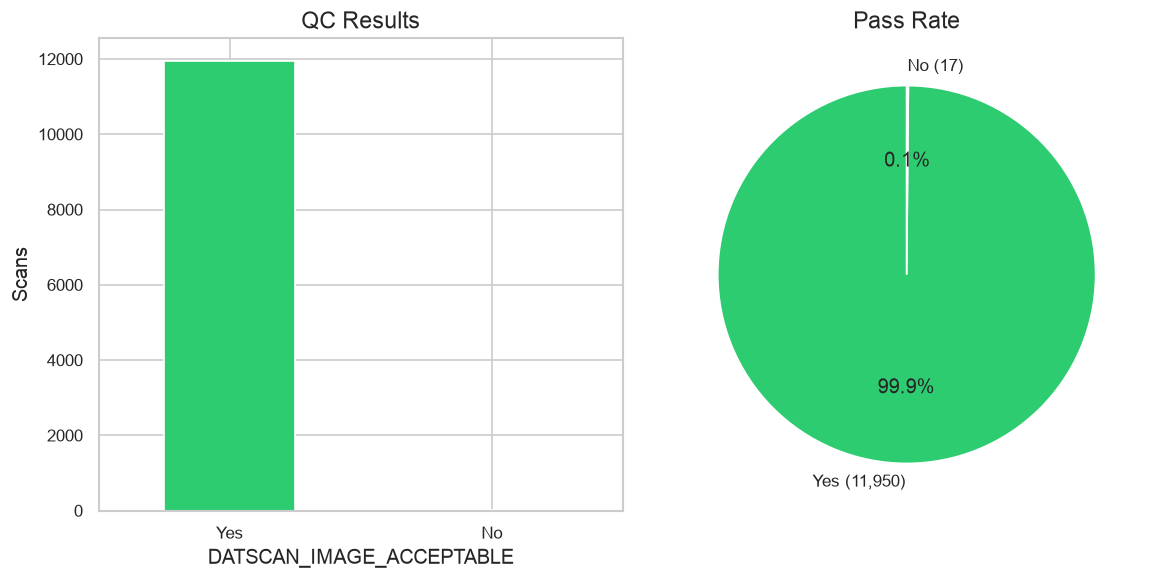

Acceptance rate: 99.9%


In [6]:
qc = acq_meta['DATSCAN_IMAGE_ACCEPTABLE'].value_counts()
colors = ['#2ecc71' if 'Yes' in str(k) else '#e74c3c' for k in qc.index]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
qc.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('QC Results'); axes[0].set_ylabel('Scans'); axes[0].tick_params(axis='x', rotation=0)
axes[1].pie(qc.values, labels=[f'{k} ({v:,})' for k,v in qc.items()],
            colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Pass Rate')
plt.tight_layout(); plt.show()
print(f'Acceptance rate: {qc.get("Yes",0)/len(acq_meta)*100:.1f}%')

## 4 · Injected Dose Distribution

Dose in MBq (megabecquerels). Should fall within a protocol range to ensure consistent imaging.

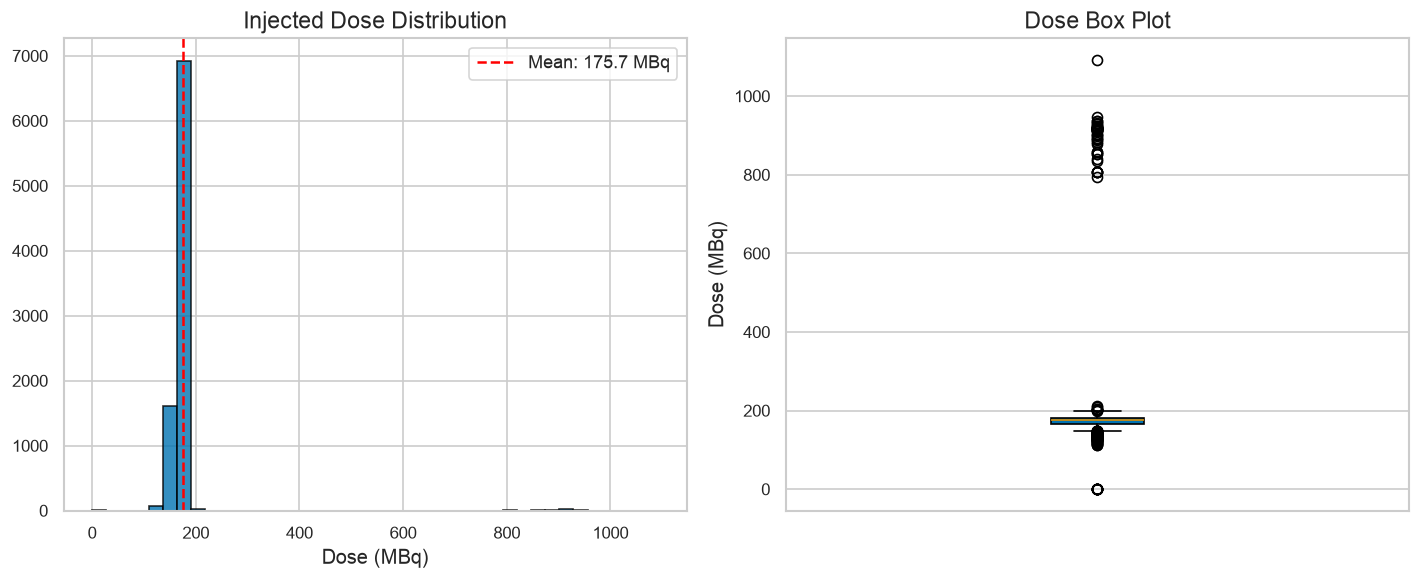

count    8683.00
mean      175.69
std        52.38
min         0.00
25%       166.94
50%       175.53
75%       180.22
max      1092.33
Name: DATSCAN_TOTAL_DOSE_CALC, dtype: float64


In [7]:
dose = acq_meta['DATSCAN_TOTAL_DOSE_CALC'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
dose.hist(bins=40, ax=axes[0], edgecolor='black', alpha=0.8, color=sns.color_palette('colorblind')[0])
axes[0].axvline(dose.mean(), color='red', linestyle='--', label=f'Mean: {dose.mean():.1f} MBq')
axes[0].set_title('Injected Dose Distribution'); axes[0].set_xlabel('Dose (MBq)'); axes[0].legend()
axes[1].boxplot(dose.values, patch_artist=True,
                boxprops=dict(facecolor=sns.color_palette('colorblind')[0]))
axes[1].set_title('Dose Box Plot'); axes[1].set_ylabel('Dose (MBq)'); axes[1].set_xticks([])
plt.tight_layout(); plt.show()
print(dose.describe().round(2))

## 5 · SBR Distributions by Brain Region

This is the core result. Higher SBR = more dopamine transporters = healthier dopamine system. The putamen is most sensitive to early PD changes.

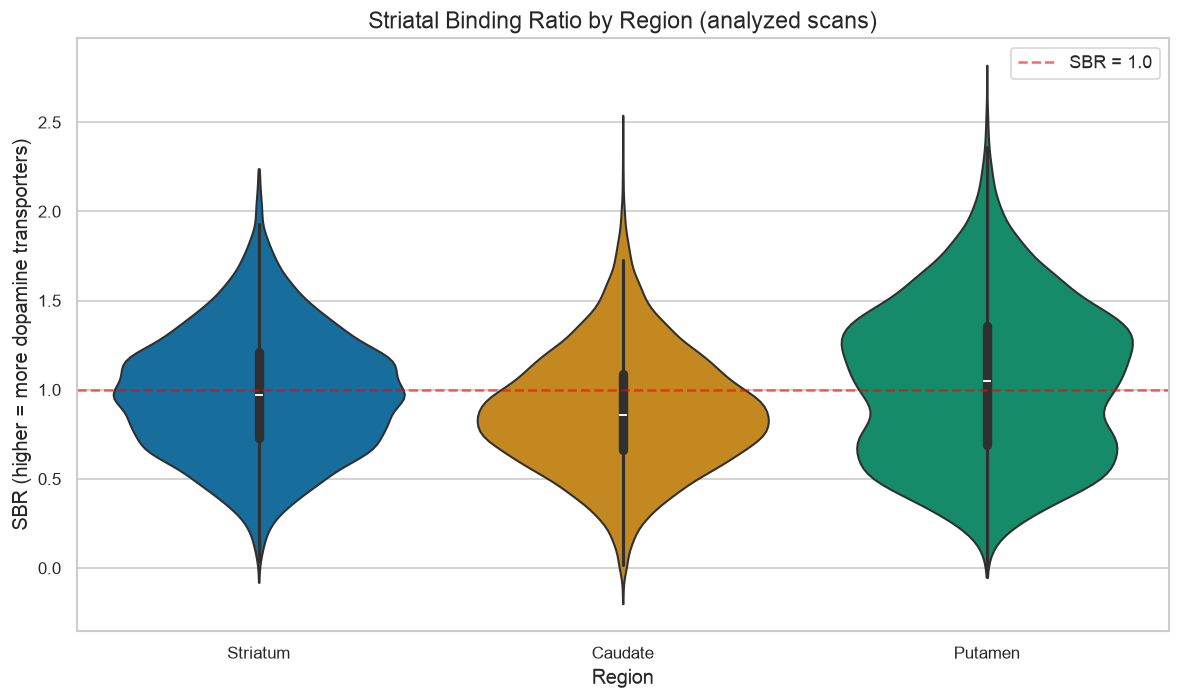

            count   mean    std   min   25%   50%   75%   max
Region                                                       
Caudate   10764.0  0.882  0.332 -0.20  0.66  0.86  1.09  2.54
Putamen   10764.0  1.045  0.439 -0.05  0.69  1.05  1.36  2.82
Striatum  10764.0  0.981  0.347 -0.08  0.73  0.97  1.21  2.24


In [8]:
sbr_valid = sbr[sbr['DATSCAN_ANALYZED'] == 'Yes'].copy()
key_cols = {c: c.replace('_REF_CWM','').replace('_',' ').title()
            for c in ['STRIATUM_REF_CWM','CAUDATE_REF_CWM','PUTAMEN_REF_CWM']
            if c in sbr_valid.columns}

plot_data = pd.concat([sbr_valid[c].rename(label) for c, label in key_cols.items()], axis=1)
melted = plot_data.melt(var_name='Region', value_name='SBR').dropna()

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=melted, x='Region', y='SBR', palette='colorblind', ax=ax, inner='box', cut=0)
ax.axhline(1.0, color='red', linestyle='--', alpha=0.6, label='SBR = 1.0')
ax.set_title('Striatal Binding Ratio by Region (analyzed scans)')
ax.set_ylabel('SBR (higher = more dopamine transporters)')
ax.legend(); plt.tight_layout(); plt.show()
print(melted.groupby('Region')['SBR'].describe().round(3))

## 6 · Left vs Right Hemisphere Asymmetry

PD often starts asymmetrically — one side more affected than the other. Points off the diagonal indicate asymmetry.

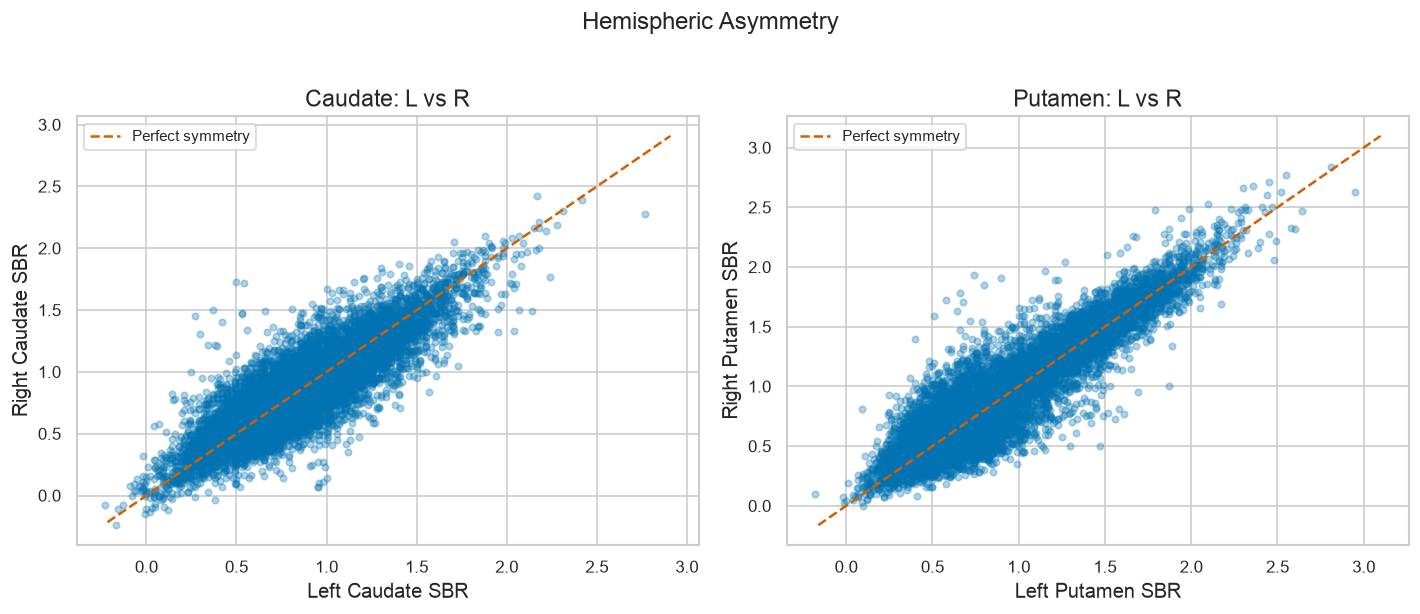

In [9]:
sbr_valid = sbr[sbr['DATSCAN_ANALYZED'] == 'Yes'].copy()
pairs = [c for c in [('CAUDATE_L_REF_CWM','CAUDATE_R_REF_CWM','Caudate'),
                      ('PUTAMEN_L_REF_CWM','PUTAMEN_R_REF_CWM','Putamen')]
         if c[0] in sbr_valid.columns]

fig, axes = plt.subplots(1, len(pairs), figsize=(6*len(pairs), 5))
if len(pairs) == 1: axes = [axes]
for ax, (lc, rc, name) in zip(axes, pairs):
    sub = sbr_valid[[lc, rc]].dropna()
    mn, mx = sub.min().min()*0.9, sub.max().max()*1.05
    ax.scatter(sub[lc], sub[rc], alpha=0.3, s=15, color=sns.color_palette('colorblind')[0])
    ax.plot([mn,mx],[mn,mx],'r--', label='Perfect symmetry')
    ax.set_xlabel(f'Left {name} SBR'); ax.set_ylabel(f'Right {name} SBR')
    ax.set_title(f'{name}: L vs R'); ax.legend(fontsize=9)
plt.suptitle('Hemispheric Asymmetry', y=1.02); plt.tight_layout(); plt.show()

## 7 · Longitudinal SBR Trends

SBR should decline over time in PD patients. Here we plot the mean across all participants — the trend reflects the mixed cohort (PD + prodromal + healthy controls).

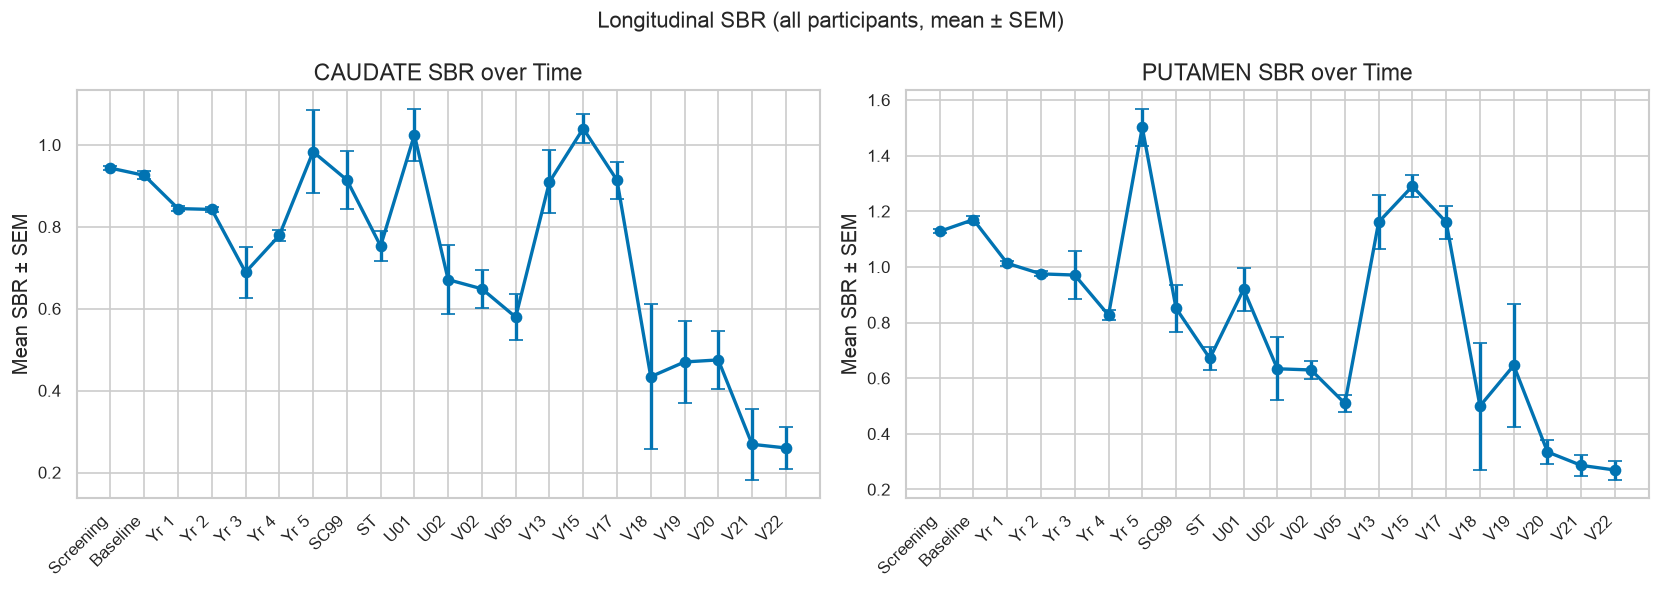

In [10]:
sbr_valid = sbr[sbr['DATSCAN_ANALYZED'] == 'Yes'].copy()
lon_cols = [c for c in ['CAUDATE_REF_CWM','PUTAMEN_REF_CWM'] if c in sbr_valid.columns]
visits = ordered_visits(sbr_valid['EVENT_ID'])

if lon_cols:
    fig, axes = plt.subplots(1, len(lon_cols), figsize=(7*len(lon_cols), 5))
    if len(lon_cols) == 1: axes = [axes]
    for ax, col in zip(axes, lon_cols):
        stats = sbr_valid.groupby('EVENT_ID')[col].agg(['mean','sem']).reindex(visits).dropna()
        x = range(len(stats))
        ax.errorbar(x, stats['mean'], yerr=stats['sem'], marker='o', linewidth=2, capsize=4,
                    color=sns.color_palette('colorblind')[0])
        ax.set_xticks(list(x))
        ax.set_xticklabels([VISIT_LABELS.get(v,v) for v in stats.index], rotation=45, ha='right')
        ax.set_ylabel('Mean SBR ± SEM')
        ax.set_title(col.split('_')[0] + ' SBR over Time')
    plt.suptitle('Longitudinal SBR (all participants, mean ± SEM)', fontsize=13)
    plt.tight_layout(); plt.show()

## 8 · Visual Interpretation: Positive vs Negative

An expert radiologist reviewed every scan and gave a binary judgment: does the uptake pattern look abnormal (positive = likely PD-like)?

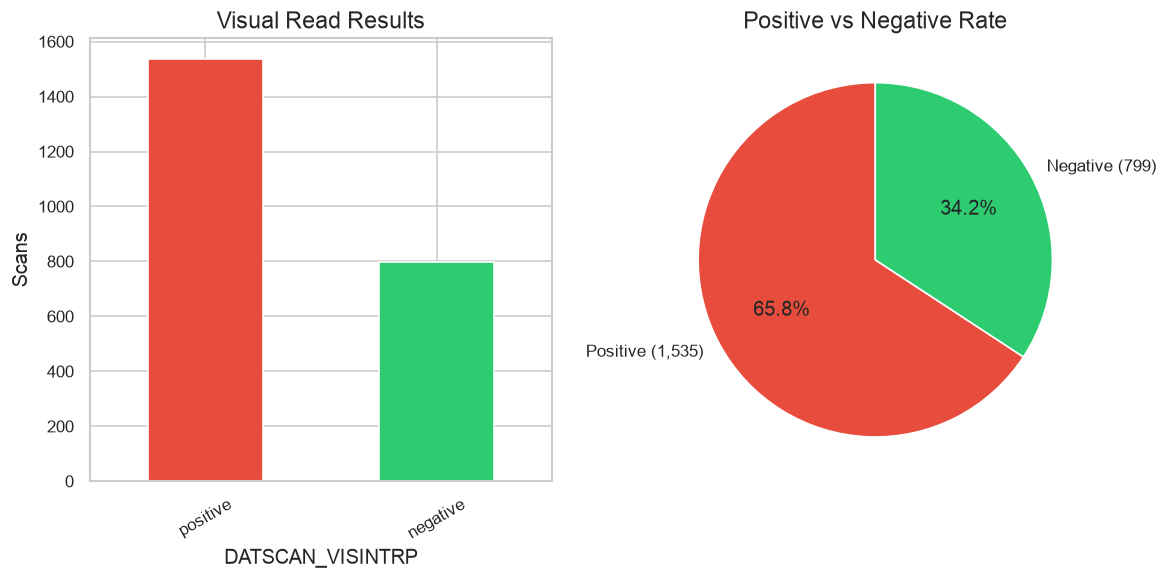

DATSCAN_VISINTRP
positive    1535
negative     799
Name: count, dtype: int64


In [11]:
vr = vis_read['DATSCAN_VISINTRP'].str.strip().str.lower().value_counts()
colors = ['#e74c3c' if 'pos' in k else '#2ecc71' for k in vr.index]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
vr.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('Visual Read Results'); axes[0].set_ylabel('Scans')
axes[0].tick_params(axis='x', rotation=30)
axes[1].pie(vr.values, labels=[f'{k.title()} ({v:,})' for k,v in vr.items()],
            colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Positive vs Negative Rate')
plt.tight_layout(); plt.show(); print(vr)

## 9 · SBR Region Correlation Heatmap

How correlated are measurements across different brain regions? We expect left-right pairs to be highly correlated, and caudate/putamen to be moderately correlated.

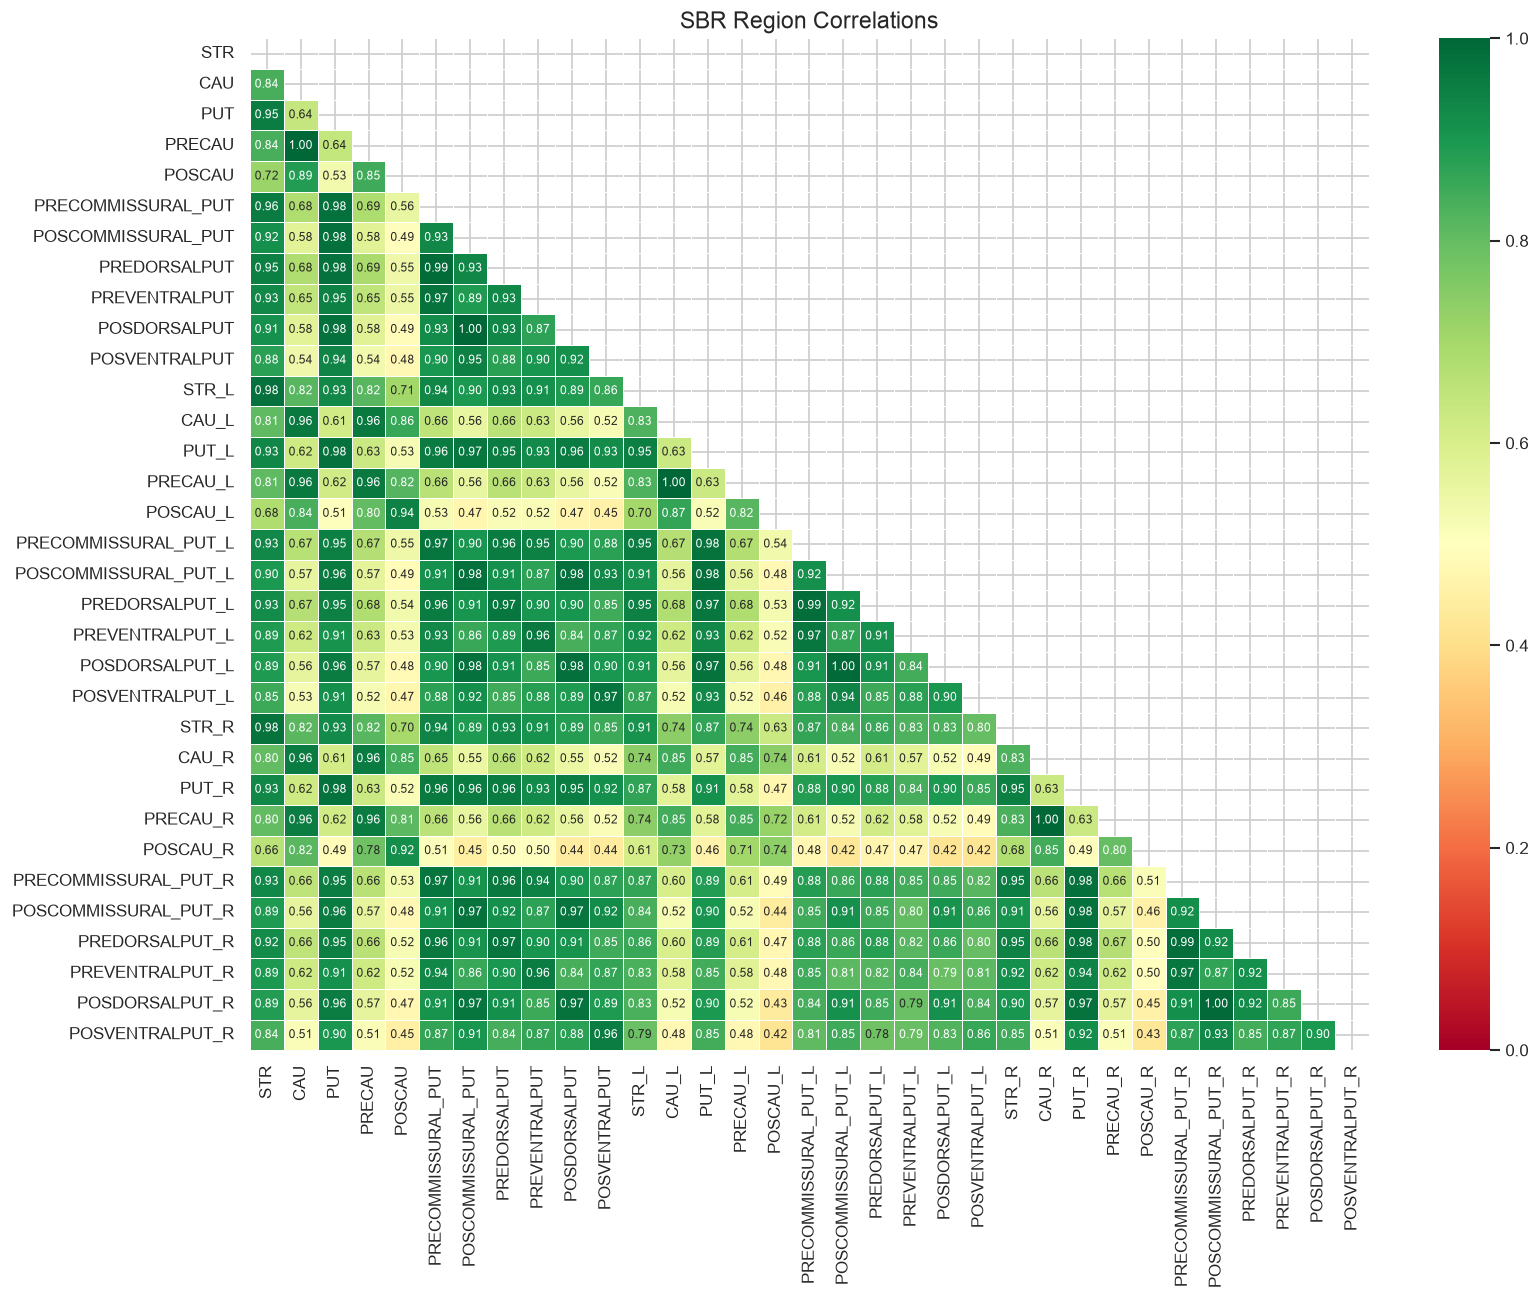

In [12]:
sbr_valid = sbr[sbr['DATSCAN_ANALYZED'] == 'Yes'].copy()
sbr_num = sbr_valid.select_dtypes(include='number').drop(columns=['PATNO','PROTOCOL'], errors='ignore')
sbr_num = sbr_num.dropna(axis=1, thresh=len(sbr_num)//2)
short = {c: c.replace('_REF_CWM','').replace('STRIATUM','STR').replace('CAUDATE','CAU')
              .replace('PUTAMEN','PUT').replace('PRECAUDATE','PRECAU')
              .replace('POSTCAUDATE','POSCAU').replace('ANTPUTAMEN','ANTPUT')
              .replace('POSTPUTAMEN','POSPUT') for c in sbr_num.columns}
corr = sbr_num.rename(columns=short).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            ax=ax, linewidths=0.3, annot_kws={'size': 7})
ax.set_title('SBR Region Correlations'); plt.tight_layout(); plt.show()

## Key Takeaways

- **Putamen SBR is the most sensitive DaTSCAN measure** for early PD — it declines first and most steeply
- **High image quality acceptance rate** ensures data reliability
- **L/R asymmetry** is a PD hallmark — expect asymmetric SBR loss in PD patients
- **Longitudinal decline** is the core signal to track over time in this dataset
- **Visual read** provides a binary clinical judgment; quantitative SBR is continuous and more precise
- Next: compare by cohort (PD vs HC) once you merge in the participants file